# CS2 (국내반) --- 기말고사 기출 (2024 가을)
### Past Final Exam (practice) --- **Solution**

*2024-12-12 시행, 110분, 100점. 채점되지 않는 연습용 노트북입니다.*

> ⚠️ **실제 시험은 손코딩입니다.** 컴퓨터 없이 시험지에 손으로 코드를 씁니다.
> 바로 실행부터 하지 말고, **먼저 종이에 답을 써 본 다음** 셀에 옮겨 실행해서 맞았는지 확인하세요.

- 빈칸 `____(a)____`를 채워서 실행 (원래 시험지의 빈칸 그대로)
- 빈칸 하나에는 **한 줄**만, 수업자료와 같은 형태로 씀. 시험에서 잘못 작성한 예로 든 것:
  `i +=1; j +=2; k +=3`, `for i in range(n): j += 1`, `if i < j: max = j`
- 맨 위 **먼저 실행** 셀을 한 번 실행하면 시험에서 "그대로 사용"이라고 한 함수들
  (`gcd`, `gaussian_elimination`, `Point`, `direction` 등)이 준비됨
- 문제 제목의 "(N주차 M번 문제와 동일)"은 **그 해 수업** 기준 번호라서 올해 강의 번호와 다를 수 있음

#### 먼저 실행

시험에서 "L06_P01.py의 함수를 그대로 사용" 처럼 이미 주어진 것으로 본 함수/class들입니다. **수정하지 말고 맨 먼저 실행**합니다.

In [ ]:
#@title 먼저 실행 (시험에서 이미 주어진 것으로 본 함수/class)
import sys, os, random, urllib.request

# 3주차 파일 문제용 단어 파일 (없으면 내려받음)
for f in ["dictionary.txt", "dictionary2.txt"]:
    if not os.path.exists(f):
        urllib.request.urlretrieve("https://raw.githubusercontent.com/SuminHan/book-cs2/main/notebooks/kor/" + f, f)

# L08_P02.py
def gcd(a, b):
    if b > a:
        a, b = b, a
    while b > 0:
        a, b = b, a%b
    return a

# L06_P01.py
def gaussian_elimination(a, b):
    n = len(b)
    for p in range(n):
        q = p
        for i in range(p+1, n):
            if abs(a[i][p]) > abs(a[q][p]):
                q = i
        for j in range(n): # swapping rows p/q
            a[p][j], a[q][j] = a[q][j], a[p][j]
        b[p], b[q] = b[q], b[p]
        if a[p][p] == 0:
            return None  # no solution or infinitely many solutions
        for i in range(p+1, n):
            c = a[i][p] / a[p][p]
            for j in range(p, n):
                a[i][j] -= c * a[p][j]
            b[i] -= c * b[p]
    x = [None] * n
    for i in range(n-1, -1, -1):
        sum = 0
        for j in range(i+1, n):
            sum += a[i][j] * x[j]
        x[i] = (b[i] - sum) / a[i][i]
    return x

def copy2DList(A):
    B = []
    for i in range(len(A)):
        B.append(A[i][:])
    return B

def truncate(x, l):   # 출력 확인용: 소수 l자리로 반올림
    R = []
    for i in range(len(x)):
        R.append(round(x[i], l) + 0.0)
    return R

# L12_P02.py
class Point:
    def __init__(self, x, y):
        self.x = x
        self.y = y

class Rectangle:
    def __init__(self, left, right, bottom, top):
        self.left = left
        self.right = right
        self.bottom = bottom
        self.top = top

    def __str__(self):
        return "(" + str(self.left) + "," + str(self.bottom) \
                + ")-(" + str(self.right) + "," + str(self.top) + ")"

def direction(fr, to):
    if fr.x == to.x:
        if fr.y < to.y:
            return "UP"
        elif fr.y > to.y:
            return "DOWN"
    elif fr.y == to.y:
        if fr.x < to.x:
            return "RIGHT"
        elif fr.x > to.x:
            return "LEFT"
    assert False, "Input polygon is not rectilinear!"

polygon1 = [Point(0,1), Point(2,1), Point(2,0), Point(4,0),
            Point(4,2), Point(5,2), Point(5,4), Point(3,4),
            Point(3,5), Point(1,5), Point(1,3), Point(0,3)]   # 반시계방향
polygon2 = [Point(0,0), Point(2,0), Point(2,3), Point(0,3),
            Point(0,2), Point(1,2), Point(1,1), Point(0,1)]   # 반시계방향

print("ready")

### 1. (5 points)

Write the output of the following program.
(Recall that `+` operation on lists is defined as concatenation, e.g. `[1,2,3] + [1,5,9,7]` becomes `[1,2,3,1,5,9,7]`.)

*먼저 종이에 출력을 예측해서 적은 다음 실행해 보세요.*

In [ ]:
def P01(L):
    L.sort()
    M = []
    for i in range(len(L)):
        if L[i] not in M:
            M.append(L[i])
    return M

L = [9,1,2,1,1,3,3,4,3,5,4]
for i in range(10):
    L = P01(L + L)
print(L)

**정답:** `[1, 2, 3, 4, 5, 9]`

### 2. (5 points) (1주차 10번 문제와 동일)

Write a function `P02`:
- input parameter: an integer list `L`
- return value: a boolean
  - `True`: if all the elements in `L` are distinct
  - `False`: otherwise

In [ ]:
def P02(L):
    for i in range(len(L)):
        for j in range(i+1 , len(L)):
            if L[i] == L[j]:
                return False
    return True

print(P02([1,3,2,5,2,1]))   # False
print(P02([1,0,2,5,3,4]))   # True

### 3. (5 points) (3주차 2번 문제와 동일)

A word is called a palindrome if it reads the same backward or forward (e.g. `"deified"`, `"malayalam"`, `"abccba"`).
Write a function `P03` (along with `isPalindrome`):
- input parameter: a string `filename`
- return value: the longest palindrome in the file; if there is a tie, return the first occurrence
  - 가장 긴 palindrome이 두개 이상 있으면 가장 먼저 나타나는 것

In [ ]:
def isPalindrome(s):
    n = len(s)
    for i in range(n//2):
        if s[i] != s[n-1-i]:
            return False
    return True

def P03(filename):
    words = open(filename,"r").read().split()
    s = ""
    for i in range(len(words)):
        if isPalindrome(words[i]):
            if len(s) < len(words[i]):
                s = words[i]
    return s

print(P03("dictionary.txt"))    # malayalam
print(P03("dictionary2.txt"))   # deified

### 4. (5 points) (4주차 6번 문제와 동일)

Write a function `P04`:
- input parameter: a boolean list that represents a 2-dimensional minefield
- return value: the list that represents the 2-dimensional array of integers storing the count of bombs in each neighborhood
  - The neighborhood for a location includes the location itself and its eight adjacent locations

In [ ]:
def withinBoundary(height, width, i, j):
    return i>=0 and i<height and j>=0 and j<width

def P04(mineField):
    h = len(mineField)
    w = len(mineField[0])
    mines = [ [None]*w for i in range(h) ]
    for i in range(h):
        for j in range(w):
            mines[i][j] = 0
            for p in range(i-1,i+2):
                for q in range(j-1,j+2):
                    if withinBoundary(h, w, p, q):
                        if mineField[p][q]:
                            mines[i][j] += 1
    return mines

print(P04([[True, False, False],
           [False, False, True]]))   # [[1, 2, 1], [1, 2, 1]]

### 5. (5 points) (4주차 8번 문제와 동일)

Write a function `P05`:
- input parameter: two matrices `A` and `B` that are represented by 2-dimensional lists
- return value: the 2-dimensional list that represents the matrix product $A \cdot B$
- † If the matrix product $A \cdot B$ is not well-defined (due to incompatible dimensions), then return `None`

In [ ]:
def P05(A,B):
    m, p = len(A), len(A[0])
    q, n = len(B), len(B[0])
    if p != q:
        return None
    C = [ [0]*n for i in range(m) ]
    for i in range(m):
        for j in range(n):
            for k in range(p):
                C[i][j] += A[i][k]*B[k][j]
    return C

A = [ [1,2,3],
      [4,5,6] ]
B = [ [7,8],
      [9,10],
      [11,12] ]
print(P05(A,A))   # None
print(P05(A,B))   # [[58, 64], [139, 154]]

### 6. (5 points) (6주차 1번 문제와 동일)

Write a function `P06`:
- input parameter: `a` and `b` where
  - `a`: two-dimensional list of integers that represents an n-by-n matrix
  - `b`: list of n integers
- return value: a length-n list `x` of float numbers where `x` represents the unique solution to the linear system of equations
  (`None` if the system has no solution or infinitely many solutions)

$$\begin{pmatrix} a[0][0] & \cdots & a[0][n-1] \\ \vdots & \ddots & \vdots \\ a[n-1][0] & \cdots & a[n-1][n-1] \end{pmatrix} \begin{pmatrix} x[0] \\ \vdots \\ x[n-1] \end{pmatrix} = \begin{pmatrix} b[0] \\ \vdots \\ b[n-1] \end{pmatrix}$$

In [ ]:
def P06(a, b):
    n = len(b)

    for p in range(n):
        q = p
        for i in range(p+1, n):
            if abs(a[i][p]) > abs(a[q][p]):
                q = i
        for j in range(n): # swapping rows p/q
            a[p][j], a[q][j] = a[q][j], a[p][j]
        b[p], b[q] = b[q], b[p]

        if a[p][p] == 0:
            return None # no solution or infinitely many solutions

        for i in range(p+1 , n):
            c = a[i][p] / a[p][p]
            for j in range(p, n):
                a[i][j] -= c * a[p][j]
            b[i] -= c * b[p]

    x = [None] * n
    for i in range(n-1, -1, -1):
        sum = 0
        for j in range(i+1 , n):
            sum += a[i][j] * x[j]
        x[i] = (b[i] - sum) / a[i][i]

    return x

print(truncate(P06([[0,1,1], [2,4,-2], [0,3,15]], [4,2,36]), 1))   # [-1.0, 2.0, 2.0]
print(truncate(P06([[1,0,1,4], [2,-1,1,7], [-2,1,0,-6], [1,1,1,9]], [1,2,3,4]), 1))   # [-8.8, -5.0, 3.4, 1.6]
print(P06([[0,1,1], [2,4,-2], [2,5,-1]], [4,2,36]))   # None

### 7. (5 points) (6주차 3번 문제와 동일)

이 문제에서는 $n-1$차 다항함수 $f: \mathbb{Z} \to \mathbb{Z}$의 함수값 $f(0), f(1), \cdots, f(n-1)$들이 주어졌을 때, $f(n)$을 계산하는 것을 목표로 한다. 다음과 같이 정의된 함수 `P07`을 완성하라:
- 입력: 정수 리스트 `L`
  - `n = len(L)`로 둘 때, 어떤 $n-1$차 다항함수 $f$가 존재하여, 각 `L[i]`는 $f(i)$를 나타냄. 즉, `L` $= [f(0), f(1), \cdots, f(n-1)]$
- 리턴값: $f(n)$
  - 입력 조건을 만족하는 $n-1$차 다항함수 $f$가 존재하지 않거나 여러개 존재할 경우에는 `None`
- † 아래 코드의 `P06`은 6번 문제의 `P06`을 그대로 불러 쓴 것 (시험지에는 `from P06 import P06`)

In [ ]:
def P07(L):
    n = len(L)
    a = [[0]*n for i in range(n)]
    b = L[:]
    for i in range(n):
        for j in range(n):
            a[i][j] = i**j
    c = P06(a, b)

    assert c != None   # refer to your math textbook (Vandermonde matrix)
    if c[n-1] == 0:
        return None

    sum = c[0]
    for j in range(1,n):
        sum += c[j] * n**j
    return sum

print(round(P07([0, 1, 4]), 4))       # 9.0     (f(x) = x²)
print(round(P07([1, 2, 9, 28]), 4))   # 65.0    (f(x) = x³ + 1)
print(P07([3, 3, 3]))                 # None    (상수함수: 2차가 아님)

### 8. (5 points) (8주차 2번 문제와 동일)

Write functions in the `Rational` class.
1. `reduce` is a modifier:
   - input parameter: `self`
   - action: convert `self` to the irreducible fraction (최대공약수로 약분)
   - return value: 없음
2. `mul` is a pure function:
   - input parameter: `self` and `r` (both are `Rational` objects)
   - return value: a new `Rational` object that represents the product of `self` and `r` (in the form of irreducible fraction)
     - 반드시 곱셈 결과를 최대공약수로 약분
     - Pure function 형태로 만들어야 하므로 `self`와 `r`은 변경하면 안됨

In [ ]:
class Rational:
    def __init__(self, n, d):
        if d > 0:
            self.n = n
            self.d = d
        else:
            self.n = -n
            self.d = -d

    def __str__(self):
        return str(self.n) + "/" + str(self.d)

    def reduce(self):
        g = gcd(self.n, self.d)    # L08_P02.py의 gcd 함수를 그대로 사용
        self.n //= g
        self.d //= g

    def mul(self, r):
        q = Rational(self.n*r.n , self.d*r.d)
        q.reduce()
        return q

def P08():
    r1 = Rational(3,4)
    r2 = Rational(2,3)
    print(r1.mul(r2))   # 1/2
    print(r1, r2)       # 3/4 2/3  (pure function이므로 그대로)

P08()

### 9. (5 points) (9주차 1번 문제와 동일)

Write functions that work on the class `Person`.
1. `engage` is a modifier:
   - input parameter: `self` and `p` (both are `Person` objects)
   - action: `self`와 `p`가 서로 파트너 관계가 되도록 `self.partner`와 `p.partner`를 적당히 설정
   - return value: 없음
2. `breakUp` is a modifier:
   - input parameter: `self`
   - action: `self`와 `self.partner`의 파트너 관계를 서로 끊음 (끊는 순서에 주의)
   - return value: 없음

In [ ]:
class Person(object):
    def __init__(self, name, gender):
        self.name = name
        self.prefList = None
        self.partner = None

    def engage(self, p):
        self.partner = p
        p.partner = self

    def breakUp(self):
        self.partner.partner = None
        self.partner = None

m = Person("m0", "male")
w = Person("w0", "female")
m.engage(w)
print(m.partner.name, w.partner.name)   # w0 m0
w.breakUp()
print(m.partner, w.partner)             # None None

### 10. (5 points) (9주차 6번 문제와 동일)

HW #2에서 일대다(one-to-many) 상황에서의 stable matching 문제에 대한 알고리즘을 다루었는데, 이 문제에서는 임의로 주어진 matching이 stability 조건을 만족하는지 여부를 판단하는 것을 고려한다.
HW #2에서 stable matching은 perfection 조건을 만족하고 다음 조건을 추가로 만족하는 matching으로 정의되었다:

(†) 다음 조건들을 모두 만족하는 $(T_i, T_{i'}, S_j, S_{j'})$가 존재하지 않아야 한다:
- $i \ne i'$이고 $j \ne j'$이다.
- 학생 $S_{j'}$는 교사 $T_i$에게 매칭되어 있다.
- 학생 $S_j$는 교사 $T_{i'}$에게 매칭되어 있다.
- 교사 $T_i$는 학생 $S_{j'}$보다 학생 $S_j$를 선호한다.
- 학생 $S_j$는 교사 $T_{i'}$보다 교사 $T_i$를 선호한다.

다음과 같이 정의된 함수 `P10`을 완성하라:
- 입력: `Teacher` object들의 리스트와 `Student` object들의 리스트
  - 문제를 간단하게 하기 위해 perfection 조건을 만족하는 matching만 입력으로 주어진다.
- 리턴값: 주어진 매칭이 stable하면 `True`, 그렇지 않으면 `False`

In [ ]:
class Teacher(object):
    def __init__(self, quota):
        self.prefList = None
        self.apprentice = []

    def prefer(self, p, q):
        return self.prefList.index(p) < self.prefList.index(q)

class Student(object):
    def __init__(self, id):
        self.prefList = None
        self.advisor = None

    def prefer(self, p):
        return self.prefList.index(p) < self.prefList.index(self.advisor)

def P10(teachers, students):
    n = len(teachers)
    m = len(students)
    for j1 in range(m):
        for j2 in range(m):
            if j2 == j1:
                continue
            s1 = students[j1]
            s2 = students[j2]
            t2 = s1.advisor
            t1 = s2.advisor
            if t1 != t2 and t1.prefer(s1,s2) and s1.prefer(t1):
                return False
    return True

# ===== 확인용 =====
# T0(정원 2), T1(정원 1), 학생 S0, S1, S2
def makeMatch(groups):   # groups[i]: 교사 i에게 배정된 학생 번호들
    T = [Teacher(2), Teacher(1)]
    S = [Student(0), Student(1), Student(2)]
    T[0].prefList = [S[0], S[1], S[2]]
    T[1].prefList = [S[2], S[0], S[1]]
    for s in S:
        s.prefList = [T[0], T[1]]          # 모든 학생이 T0를 더 선호
    for i in range(2):
        for j in groups[i]:
            T[i].apprentice.append(S[j])
            S[j].advisor = T[i]
    return T, S

print(P10(*makeMatch([[0,1], [2]])))   # True
print(P10(*makeMatch([[0,2], [1]])))   # False  (T0와 S1이 unstable)
print(P10(*makeMatch([[1,2], [0]])))   # False  (T0와 S0이 unstable)

### 11. (5 points) (11주차 2번 문제와 동일)

Write functions for poker (with 5 cards/hand):
1. `hasConsecutivePositive`:
   - 나머지 함수들에 의해 제대로 이용될 수 있게 구현
   - † 10, Jack, Queen, King, Ace도 straight(또는 straight flush)로 처리될 수 있게 해야 함에 주의
2. `flush`:
   - input parameter: a `Hand` object `hand`
   - return value: `True` if `hand` is "flush", `False` otherwise
3. `straight`:
   - input parameter: a `Hand` object `hand`
   - return value: `True` if `hand` is "straight", `False` otherwise

In [ ]:
class Card:
    def __init__(self, suit, rank):
        self.suit = suit
        self.rank = rank

class Hand:
    def __init__(self, cards):
        self.cards = cards

    def rankList(self):
        L = [0]*13
        for i in range(len(self.cards)):
            j = self.cards[i].rank
            assert 1 <= j <= 13
            L[j-1] += 1
        return L

    def suitList(self):
        L = [0]*4
        for i in range(len(self.cards)):
            j = self.cards[i].suit
            assert 0 <= j <= 3
            L[j] += 1
        return L

def hasConsecutivePositive(L, k):
    n = len(L)
    count = 0
    for i in range(n+1):
        if L[i%n] >= 1:
            count += 1
            if count == k:
                return True
        else:
            count = 0
    return False

def f(hand):
    L = hand.rankList()
    return hasConsecutivePositive(L, 5)

def g(hand):
    L = hand.suitList()
    for i in range(len(L)):
        if L[i] == 5:
            return True
    return False

def flush(hand):
    return g(hand) and not f(hand)

def straight(hand):
    return f(hand) and not g(hand)

royal  = Hand([Card(0,10), Card(1,11), Card(2,12), Card(3,13), Card(0,1)])   # 10-J-Q-K-A
fl     = Hand([Card(2,2), Card(2,9), Card(2,4), Card(2,13), Card(2,7)])
sflush = Hand([Card(1,5), Card(1,6), Card(1,7), Card(1,8), Card(1,9)])
print(straight(royal), straight(fl), straight(sflush))   # True False False
print(flush(fl), flush(royal), flush(sflush))            # True False False

### 12. (5 points) (11주차 3번 문제와 동일)

Write functions for poker (with 5 cards/hand):
1. `fullHouse`:
   - input parameter: a `Hand` object `hand`
   - return value: `True` if `hand` is "full house", `False` otherwise
2. `twoPair`:
   - input parameter: a `Hand` object `hand`
   - return value: `True` if `hand` is "two pair", `False` otherwise

(`Card`, `Hand`는 11번과 같음)

In [ ]:
def h(hand, num):
    L = hand.rankList()
    for i in range(len(L)):
        if L[i] == num:
            return True
    return False

def fullHouse(hand):
    return h(hand,3) and h(hand,2)

def twoPair(hand):
    L = hand.rankList()
    count = 0
    for i in range(len(L)):
        if L[i] == 2:
            count += 1
    return count == 2

house = Hand([Card(0,3), Card(1,3), Card(2,3), Card(0,9), Card(1,9)])
two   = Hand([Card(0,3), Card(1,3), Card(2,5), Card(0,9), Card(1,9)])
one   = Hand([Card(0,3), Card(1,3), Card(2,5), Card(0,9), Card(1,8)])
print(fullHouse(house), fullHouse(two))           # True False
print(twoPair(two), twoPair(house), twoPair(one)) # True False False

### 13. (5 points) (12주차 1번 문제와 동일)

Write a function `P13`:
- input parameter: a list of `Point` objects that represents a rectilinear polygon
- return value: `"CW"` if `Point` object들이 시계방향(clockwise)으로 돌 때, `"CCW"` if 반시계방향(counter-clockwise)으로 돌 때

In [ ]:
def P13(polygon):
    n = len(polygon)
    top = polygon[0].y
    for i in range(1,n):
        if top < polygon[i].y:
            top = polygon[i].y

    for i in range(n):
        fr = polygon[i]
        to = polygon[(i+1)%n]
        if top == fr.y and top == to.y:
            if fr.x > to.x:
                return "CCW"
            else:
                return "CW"

print(P13(polygon1), P13(polygon2))               # CCW CCW
print(P13(polygon1[::-1]), P13(polygon2[::-1]))   # CW CW  ([::-1]: 순서를 거꾸로)

### 14. (5 points) (12주차 2번 문제에서 polygon orientation만 변경하고 나머지는 동일)

Write a function `P14`:
- input parameter: a list of `Point` objects that represents a rectilinear polygon
  - `L12_P02.py`에서와 달리 **시계방향**으로 돌아가는 입력만 주어짐
- return value:
  - 하나의 CCTV로 전체 지역이 감시가능하면: 설치가능지역을 나타내는 `Rectangle` object
  - 하나의 CCTV로 전체 지역이 감시불가능하면: `None`
- `Point`/`Rectangle` class, `direction` 함수는 `L12_P02.py`에 주어진 것과 동일

In [ ]:
def P14(polygon):
    l = -sys.maxsize
    r = sys.maxsize
    b = -sys.maxsize
    t = sys.maxsize
    n = len(polygon)

    for i in range(n):
        fr = polygon[i]
        to = polygon[(i+1)%n]
        dir = direction(fr, to)

        if dir == "DOWN":
            r = min(r, fr.x)
        elif dir == "UP":
            l = max(l, fr.x)
        elif dir == "LEFT":
            b = max(b, fr.y)
        elif dir == "RIGHT":
            t = min(t, fr.y)

    if l < r and b < t:
        return Rectangle(l, r, b, t)
    else:
        return None

print(P14(polygon1[::-1]))   # (2,2)-(3,3)   (polygon1을 시계방향으로 바꾼 것)
print(P14(polygon2[::-1]))   # None

### 15. (30 points)

다음과 같이 $n$개의 컴퓨터 $C_0, C_1, \cdots, C_{n-1}$과 $n$개의 모니터 $M_0, M_1, \cdots, M_{n-1}$을 연결하는 상황을 고려하자.
- 각 컴퓨터 $C_i$의 영상 출력 단자에는 케이블 $A_i$가 연결되어 있다.
- 각 모니터 $M_k$의 입력 단자에는 케이블 $B_k$가 연결되어 있다.
- 각 $A_i$와 각 $B_k$는 아래 그림과 같이 스위치 $S_{ik}$를 통해 연결되어 있다.
  - $S_{ik}$ 이외의 지점에서는 $A_i$와 $B_k$가 접촉하지 않는다.
  - $A_i$는 $S_{ik}$와 수직방향으로 연결되며, $C_i$에서 출력되는 전류 신호가 $S_{ik}$의 아래에서 위로 올라가는 방향으로 연결된다.
  - $B_k$는 $S_{ik}$와 수평방향으로 연결되며, 전류 신호가 $S_{ik}$의 왼쪽에서 오른쪽으로 흘러서 $M_k$로 입력되는 방향으로 연결된다.

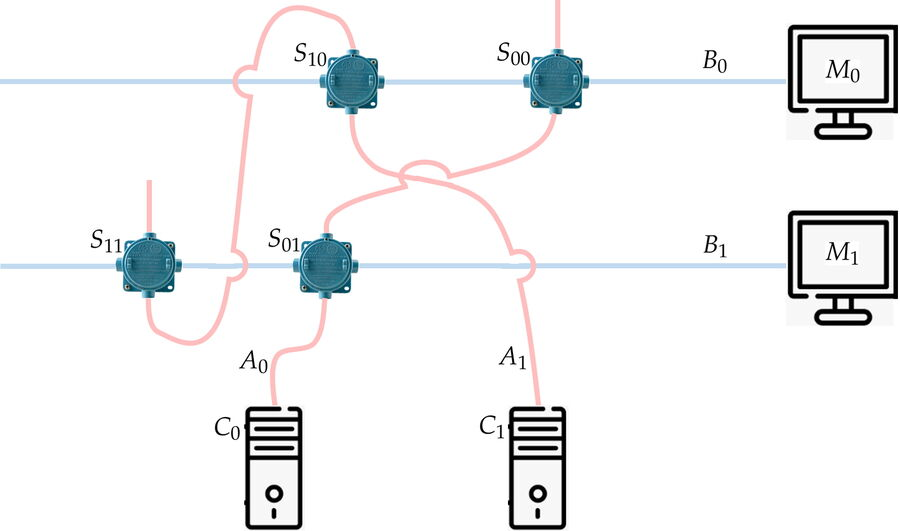

- 각 스위치 $S_{ik}$는 아래 그림과 같이 (a), (b), (c) 중 하나로 설정할 수 있다.
  - (a): $S_{ik}$의 좌측에서 우측 방향으로 $B_k$의 전류가 흐름 ($A_i$와 $B_k$의 접촉이 분리됨)
  - (b): $S_{ik}$의 하단에서 상단 방향으로 $A_i$의 전류가 흐름 ($A_i$와 $B_k$의 접촉이 분리됨)
  - (c): $S_{ik}$의 하단에서 우측 방향으로 $A_i$의 전류가 $B_k$로 타고 흐름
  - (a), (b), (c) 모두에 대해, 입력 전류가 없으면 출력 전류도 당연히 없음

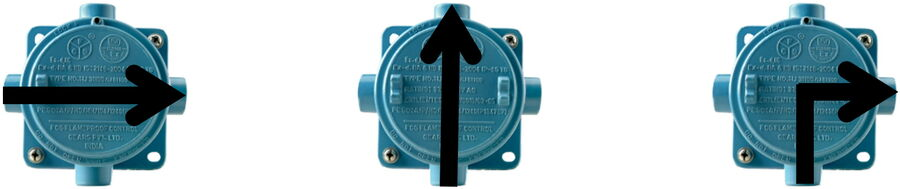

*(왼쪽부터 (a), (b), (c))*

- 각 $A_i$에 대해 어떤 일대일 대응 $\sigma_i: \{0, \cdots, n-1\} \to \{0, \cdots, n-1\}$가 존재하여, $A_i$는 ($C_i$에서 시작하여) $B_{\sigma_i(0)}, B_{\sigma_i(1)}, \cdots, B_{\sigma_i(n-1)}$ 순서로 (스위치들을 통해) 연결된다.
  - 위 그림의 예의 경우, $\sigma_0(0) = 1, \sigma_0(1) = 0, \sigma_1(0) = 0, \sigma_1(1) = 1$이다.
- 각 $B_k$에 대해 어떤 일대일 대응 $\tau_k$가 존재하여, $B_k$는 (좌측에서 우측 방향 기준으로) $A_{\tau_k(0)}, A_{\tau_k(1)}, \cdots, A_{\tau_k(n-1)}$ 순서로 (스위치들을 통해) 연결된다.
  - 위 그림의 예의 경우, $\tau_0(0) = 1, \tau_0(1) = 0, \tau_1(0) = 1, \tau_1(1) = 0$이다.

이와 같이 주어진 연결 패턴에 대해 다음 조건을 만족하도록 각 스위치 $S_{ik}$를 (a), (b), (c) 중 하나로 설정하려고 한다.

(†) 어떤 일대일 대응 $\pi$가 존재하여, 각 컴퓨터 $C_i$에서 나가는 전류 신호는 모니터 $M_{\pi(i)}$로 들어간다.
(스위치들을 어떤 조합으로 설정하더라도 한 컴퓨터의 출력 전류가 두 대 이상의 모니터로 입력되는 경우는 발생할 수 없다.)

아래 그림은 $\pi(0) = 1, \pi(1) = 0$이 되도록 스위치들을 설정한 예를 보여준다.
- $S_{10}$은 (c) 형태로 설정하여 $C_1$의 출력 전류가 $A_1$을 거쳐 $B_0$으로 흐르게 한다.
- $S_{00}$은 수평방향인 (a) 형태로 설정하여 $S_{10}$에서 수평방향으로 나온 전류가 $M_0$으로 흐르게 한다.
- $S_{01}$은 (c) 형태로 설정하여 $C_0$의 출력 전류가 $A_0$과 $B_1$을 거쳐 $M_1$로 흐르게 한다.
- 이와 같이 설정하면 $S_{11}$로는 전류가 흐르지 않으므로 $S_{11}$은 아무렇게나 설정하면 된다.

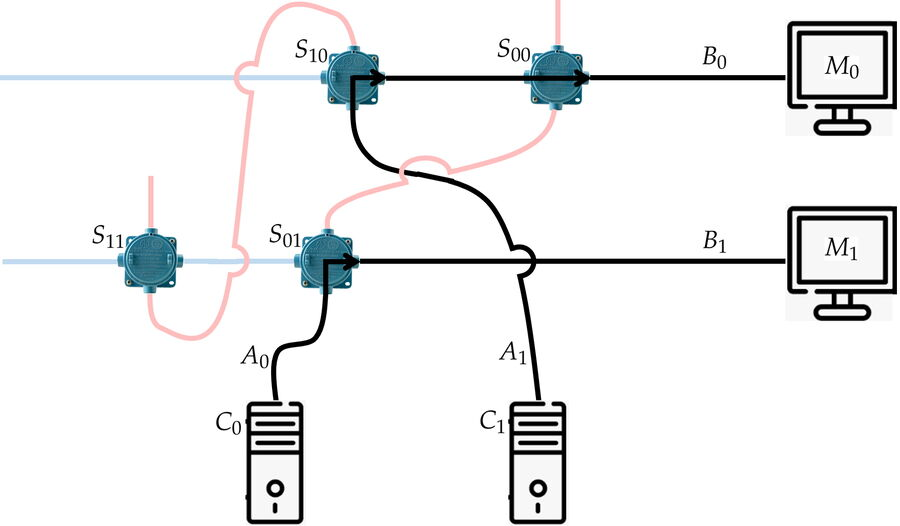

아래 그림은 $\pi(0) = 0, \pi(1) = 1$이 되도록 스위치들을 설정하는 것은 불가능함을 보여준다.
- $C_0$과 $M_{\pi(0)} (= M_0)$이 연결되도록 하려면 $S_{01}$은 수직방향인 (b) 형태로 설정해야만 한다.
- $C_1$과 $M_{\pi(1)} (= M_1)$이 연결되도록 하려면 $S_{01}$은 수평방향인 (a) 형태로 설정해야만 한다.

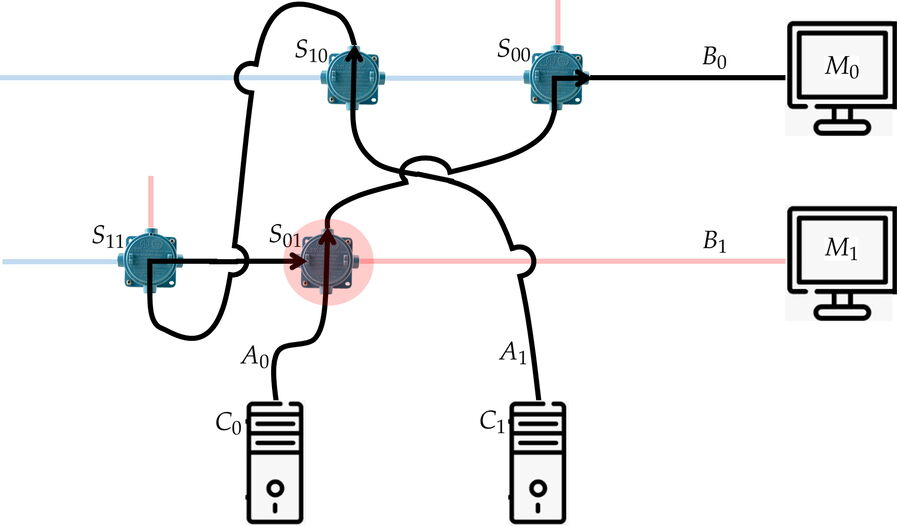

이 문제에서는 임의로 주어진 $\sigma_0, \cdots, \sigma_{n-1}, \tau_0, \cdots, \tau_{n-1}$에 대해 조건 (†)를 만족하는 $\pi$를 찾는 것을 목표로 한다. 다음과 같은 함수 `P15`를 작성하고 정확성을 증명하라.
- 입력: $\sigma_0, \cdots, \sigma_{n-1}, \tau_0, \cdots, \tau_{n-1}$를 나타내는 n-by-n 2차원 리스트 `sigma`, `tau`
  - 각 `sigma[i][j]`는 $\sigma_i(j)$를 나타내고, 각 `tau[i][j]`는 $\tau_i(j)$를 나타낸다.
  - 그림의 예의 경우 `sigma = [[1,0],[0,1]]`, `tau = [[1,0],[1,0]]`
  - $2 \le n \le 300$
- 리턴값: 조건 (†)를 만족하는 $\pi$를 나타내는 리스트 `pi` $= [\pi(0), \pi(1), \cdots, \pi(n-1)]$
  - 그림의 예의 경우 `pi = [1,0]`
  - 답이 여러개 있으면, 아무거나 하나 리턴하면 됨
  - 모든 입력에 대해 답이 항상 존재하는데, 이 점도 증명해야 함

주의사항:
- 코드 길이에 제한은 없으나 10라인을 넘을 정도로 길어지면 오답을 작성하고 있을 가능성이 높다.
- $n = 300$에 이르는 큰 입력이 주어지니 $n!$개의 순열을 헤아리는 단순한 방식은 고려하면 안된다.
- 템플릿 코드에 주어진 `Person` class(의 변수/함수)와 `findMatch`를 자유롭게 이용해도 된다.
  - 수업시간에 학습한 매우 간단한 Python 기능이면 충분하다. `math` 등의 라이브러리도 전혀 필요하지 않다.
- 코드가 (운좋게) 맞다고 하더라도, 정확성 증명이 완벽하지 않으면 0점 처리
- 코드를 단순하게 하기 위해 $\pi$만 리턴하도록 요구하였는데, $\pi$에 대응되는 $S_{ik}$들의 설정은 정확성 증명에서 등장해야 할 수 밖에 없다.
  - 즉, 정확성 증명에서는 각 $S_{ik}$의 설정을 $\pi$와 함께 구성해주고, 제시한대로 $S_{ik}$들을 설정하면 실제로 $\pi$에 따라 컴퓨터-모니터 매칭이 정상적으로 이루어짐을 보여야만 한다.

In [ ]:
class Person(object):
    def __init__(self, index):
        self.index = index   # use this variable to identify the index of the partner
        self.prefList = []
        self.partner = None
        self.numProposal = 0

    # 아래 함수들과 findMatch는 L10_P01.py와 같음
    def isFree(self):
        return self.partner == None

    def engage(self, p):
        self.partner = p
        p.partner = self

    def breakUp(self):
        self.partner.partner = None
        self.partner = None

    def prefer(self, p):
        i = self.prefList.index(self.partner)
        j = self.prefList.index(p)
        return j < i

    def womanToPropose(self):
        w = self.prefList[self.numProposal]
        self.numProposal += 1
        return w

def findMatch(men, women):
    n = len(men)
    numFreeMen = n
    while numFreeMen > 0:
        for i in range(n):
            m = men[i]
            if m.isFree():
                break
        w = m.womanToPropose()
        if w.isFree():
            numFreeMen -= 1
            w.engage(m)
        elif w.prefer(m):
            w.breakUp()
            w.engage(m)

def P15(sigma, tau):
    n = len(sigma)
    men = [None] * n
    women = [None] * n
    for i in range(n):
        men[i] = Person(i)
        women[i] = Person(i)
    pi = [None]*n
    for i in range(n):
        for j in range(n):
            men[i].prefList.append(women[sigma[i][j]])
            women[i].prefList.append(men[tau[i][n-1-j]])
    findMatch(men, women)
    for i in range(n):
        pi[i] = men[i].partner.index
    return pi

# ===== 확인용 =====
# pi가 (†)를 만족하려면: A_i는 B_pi(i)를 만나기 전의 스위치를 모두 (b)로, B_k는 A_{pi^-1(k)} 뒤의 스위치를 모두 (a)로 둬야 함.
# 두 요구가 같은 스위치 S_ik에서 부딪히는지 검사
def check15(sigma, tau, pi):
    n = len(sigma)
    if sorted(pi) != list(range(n)):
        return False
    inv = [None]*n
    for i in range(n):
        inv[pi[i]] = i
    for i in range(n):
        for k in range(n):
            if k != pi[i]:
                vertical = sigma[i].index(k) < sigma[i].index(pi[i])     # S_ik는 (b)여야 함
                horizontal = tau[k].index(inv[k]) < tau[k].index(i)    # S_ik는 (a)여야 함
                if vertical and horizontal:
                    return False
    return True

sigma = [[1,0],[0,1]]
tau = [[1,0],[1,0]]
print(P15(sigma, tau))                     # [1, 0]
print(check15(sigma, tau, [0, 1]))         # False (그림의 두번째 예)
ok = True
for t in range(30):
    rng = random.Random(t)
    n = rng.randint(2, 40)
    sigma = [rng.sample(range(n), n) for i in range(n)]
    tau = [rng.sample(range(n), n) for i in range(n)]
    if not check15(sigma, tau, P15(sigma, tau)):
        ok = False
print(ok)   # True

**답안 (정확성 증명)**

(연습문제 #10-3과 문제 구조가 거의 동일하여 알고리즘과 정확성 증명도 매우 유사하다.)

문제의 입력으로 주어진 임의의 $\sigma_0, \cdots, \sigma_{n-1}, \tau_0, \cdots, \tau_{n-1}$에 대해, stable matching 문제의 입력을 다음과 같이 구성하자: 각 남자 $m_i$와 각 여자 $w_k$의 preference list를
1. $m_i$는 $w_{\sigma_i(0)}, w_{\sigma_i(1)}, \cdots, w_{\sigma_i(n-1)}$ 순서로 선호
2. $w_k$는 $m_{\tau_k(n-1)}, m_{\tau_k(n-2)}, \cdots, m_{\tau_k(0)}$ 순서로 선호

하는 것으로 설정하자. 이렇게 설정한 preference list에 대한 stable matching이 (하나 이상) 존재함은 수업 시간에 다루었는데, 이 중 아무거나 하나(예: Propose-Reject 알고리즘으로 얻은 matching)를 $M$으로 나타내고, $\pi$를 "$M$ 하에서 각 $m_i$의 파트너는 $w_{\pi(i)}$"를 만족하는 유일한 permutation으로 택하자.

$\pi$에 대응되는 $S_{ik}$들의 설정: 각 $i$에 대해 ($\sigma = \sigma_i$로 줄여 씀)
$$S_{i,\sigma(j)} = \begin{cases} \text{(b) 형태 (수직방향)} & 0 \le j < \sigma^{-1}(\pi(i)) \\ \text{(c) 형태} & j = \sigma^{-1}(\pi(i)) \ (\text{i.e. } \sigma(j) = \pi(i)) \\ \text{(a) 형태 (수평방향)} & \sigma^{-1}(\pi(i)) < j < n \end{cases}$$

이와 같이 설정하면 실제로 $\pi$에 따라 컴퓨터-모니터 매칭이 이루어짐을 보이자. 문제의 두번째 예와 같은 상황이 발생하지 않음을 보이면 충분하다. 이런 상황이 발생한다고 가정하면 아래를 모두 성립시키는 $i, k$ ($k \ne \pi(i)$)가 존재한다:
- (i) $C_i$에서 출력된 $A_i$의 전류가 (b) 형태로 설정된 $S_{ik}$를 먼저 통과하고, 이후에 (c) 형태로 설정된 $S_{i,\pi(i)}$를 거쳐 $B_{\pi(i)}$로 흐른다. 즉, $A_i$는 $B_k$를 먼저 만나고 이후에 $B_{\pi(i)}$를 만난다.
- (ii) $C_{\pi^{-1}(k)}$에서 출력된 전류가 (c) 형태로 설정된 $S_{\pi^{-1}(k),k}$를 통과하여 $B_k$로 흐른다.
- (iii) $S_{\pi^{-1}(k),k}$는 $S_{ik}$보다 왼쪽에 위치한다. 즉, 이 전류가 모니터 $M_k$에 도달하려면 (수직방향으로 설정된) $S_{ik}$를 수평방향으로 통과해야만 한다.

정리하면:
- (i)과 (1)에 의해 $m_i$는 ($M$ 하에서 파트너인) $w_{\pi(i)}$보다 $w_k$를 선호한다.
- (iii)과 (2)에 의해 $w_k$는 ($M$ 하에서 파트너인) $m_{\pi^{-1}(k)}$보다 $m_i$를 선호한다.

따라서 $(m_i, w_k)$는 $M$ 하에서 unstable pair가 되어야 하는데, 이는 $M$이 stable matching임에 모순이다.